In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("Real estate.csv")

df.head()


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [2]:

# Remove spaces and special characters
df.columns = df.columns.str.strip().str.lower().str.replace(
    r'[^a-z0-9]+', '_', regex=True
)

df.columns


Index(['no', 'x1_transaction_date', 'x2_house_age',
       'x3_distance_to_the_nearest_mrt_station',
       'x4_number_of_convenience_stores', 'x5_latitude', 'x6_longitude',
       'y_house_price_of_unit_area'],
      dtype='object')

In [3]:

df.isnull().sum()


no                                        0
x1_transaction_date                       0
x2_house_age                              0
x3_distance_to_the_nearest_mrt_station    0
x4_number_of_convenience_stores           0
x5_latitude                               0
x6_longitude                              0
y_house_price_of_unit_area                0
dtype: int64

In [4]:

df.duplicated().sum()


np.int64(0)

In [5]:

# Remove duplicates
df = df.drop_duplicates()


In [6]:

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

df.isnull().sum()


no                                        0
x1_transaction_date                       0
x2_house_age                              0
x3_distance_to_the_nearest_mrt_station    0
x4_number_of_convenience_stores           0
x5_latitude                               0
x6_longitude                              0
y_house_price_of_unit_area                0
dtype: int64

In [7]:

df1 = pd.DataFrame({
    'no': [1, 2, 3],
    'N': ['A', 'B', 'C']
})

df2 = pd.merge(df, df1, on='no', how='left')

df2.head()


,no,x1_transaction_date,x2_house_age,x3_distance_to_the_nearest_mrt_station,x4_number_of_convenience_stores,x5_latitude,x6_longitude,y_house_price_of_unit_area,N
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9,A
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2,B
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3,C
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8,NaN
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1,NaN


In [8]:

# Filter properties near MRT station
filter_data = df[df['x3_distance_to_the_nearest_mrt_station'] < 1000]

filter_data.head()


,no,x1_transaction_date,x2_house_age,x3_distance_to_the_nearest_mrt_station,x4_number_of_convenience_stores,x5_latitude,x6_longitude,y_house_price_of_unit_area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [9]:

# Select particular columns
subset_data = df[['x2_house_age',
                  'x3_distance_to_the_nearest_mrt_station',
                  'y_house_price_of_unit_area']]

subset_data.head()


,x2_house_age,x3_distance_to_the_nearest_mrt_station,y_house_price_of_unit_area
0,32.0,84.87882,37.9
1,19.5,306.59470,42.2
2,13.3,561.98450,47.3
3,13.3,561.98450,54.8
4,5.0,390.56840,43.1


In [10]:

# Create new age category
df['age_group'] = df['x2_house_age'].apply(
    lambda x: 'Old' if x > 30 else 'New'
)

df.head()


,no,x1_transaction_date,x2_house_age,x3_distance_to_the_nearest_mrt_station,x4_number_of_convenience_stores,x5_latitude,x6_longitude,y_house_price_of_unit_area,age_group
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9,Old
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2,New
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3,New
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8,New
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1,New


In [11]:

# Apply Label Encoding
label_encoder = LabelEncoder()

df['age_encoded'] = label_encoder.fit_transform(df['age_group'])

df.head()


,no,x1_transaction_date,x2_house_age,x3_distance_to_the_nearest_mrt_station,x4_number_of_convenience_stores,x5_latitude,x6_longitude,y_house_price_of_unit_area,age_group,age_encoded
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9,Old,1
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2,New,0
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3,New,0
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8,New,0
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1,New,0


In [12]:

# Average house price by age group
avg_price = df.groupby('age_group')['y_house_price_of_unit_area'].mean()

avg_price


age_group
New    38.029375
Old    37.812766
Name: y_house_price_of_unit_area, dtype: float64

In [13]:

# Total house price by age group
total_price = df.groupby('age_group')['y_house_price_of_unit_area'].sum()

total_price


age_group
New    12169.4
Old     3554.4
Name: y_house_price_of_unit_area, dtype: float64

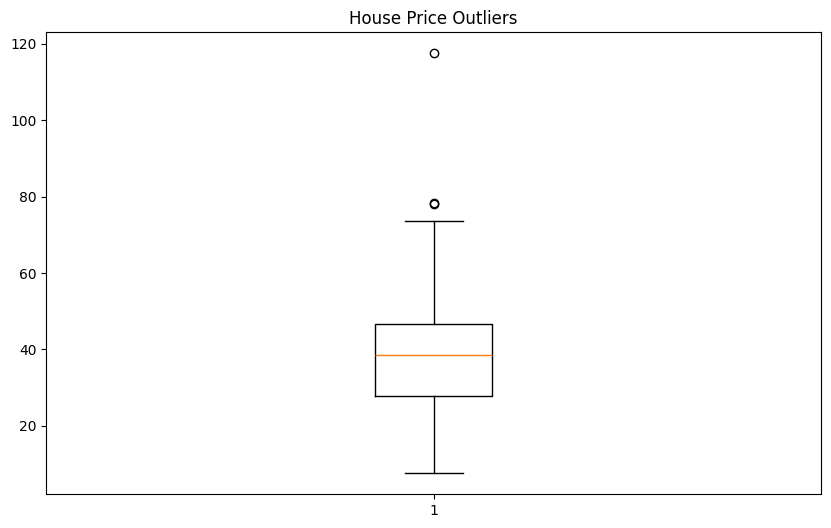

In [14]:

plt.figure(figsize=(10, 6))

plt.boxplot(df['y_house_price_of_unit_area'])

plt.title('House Price Outliers')
plt.show()


In [15]:

Q1 = df['y_house_price_of_unit_area'].quantile(0.25)
Q3 = df['y_house_price_of_unit_area'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df['y_house_price_of_unit_area'] < lower) |
    (df['y_house_price_of_unit_area'] > upper)
]

outliers


,no,x1_transaction_date,x2_house_age,x3_distance_to_the_nearest_mrt_station,x4_number_of_convenience_stores,x5_latitude,x6_longitude,y_house_price_of_unit_area,age_group,age_encoded
220,221,2013.333,37.2,186.5101,9,24.97703,121.54265,78.3,Old,1
270,271,2013.333,10.8,252.5822,1,24.97460,121.53046,117.5,New,0
312,313,2013.583,35.4,318.5292,9,24.97071,121.54069,78.0,Old,1


In [16]:

# Handle outliers
df['y_house_price_of_unit_area'] = df['y_house_price_of_unit_area'].clip(
    lower, upper
)
